# Case Study 4: Predicting Student Dropout and Academic Success

**Subject:** Fundamentals of Data Science  |  **Student:** Marru Mahathi Rao  |  **Roll No:** 160124733150

**Dataset:** `Studentdata.csv` (UCI "Predict Students' Dropout and Academic Success", 4,424 students, 36 predictors + `Target`)

**Notebook roadmap (matches the case-study tasks):** Part A data understanding and preprocessing, Part B exploratory analysis, Part C hypothesis testing, Part D classification model, Part E interpretation and recommendations.

## 1. Problem statement and objectives

A higher-education institution wants to understand which factors are associated with student **Dropout**, **Enrolled** (still studying after the normal course duration) and **Graduate** outcomes, and to build a model that predicts the outcome so that support can be planned for students at risk.

**Objectives**
1. Load, inspect and clean the data (Part A).
2. Describe the outcome distribution and compare admission grade, first-semester performance and age across outcomes (Part B).
3. Test statistically whether first-semester grades differ between outcome groups (Part C).
4. Build and evaluate a multiclass logistic regression model, paying attention to class imbalance and to which variables are really available for an *early* prediction (Part D).
5. Interpret the findings, state limitations, and give responsible, evidence-based recommendations (Part E).

**Important caution:** all findings are *associations*. Nothing in this analysis proves that a variable *causes* dropout.

## 2. Methodology
1. **Understand and clean the data (Part A):** load the semicolon-separated file, classify attributes as binary, categorical or numerical, check missing values, duplicates and unusual values, and decide the preprocessing.
2. **Explore (Part B):** outcome distribution, descriptive statistics and comparisons of admission grade, first-semester performance, age and financial factors across outcomes.
3. **Test a hypothesis (Part C):** check ANOVA assumptions and use the Kruskal-Wallis test, with effect size and post-hoc comparisons, for first-semester grades across outcomes.
4. **Model (Part D):** stratified 80/20 split, one-hot encoding and scaling inside a pipeline, multinomial logistic regression built for early prediction (no second-semester data), compared with a balanced-weight version, a full-information model and a Random Forest, and checked with 5-fold cross-validation.
5. **Interpret (Part E):** coefficients, limitations, recommendations and responsible use.

## Part A: Data understanding and preprocessing

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support, f1_score)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
ORDER = ["Dropout", "Enrolled", "Graduate"]
PALETTE = {"Dropout": "#d95f5f", "Enrolled": "#e8b84b", "Graduate": "#4f9d69"}

### Task 1-2: Load the dataset and inspect it
The file is **semicolon-separated** (`sep=";"`), and one column name (`Daytime/evening attendance`) contains a hidden tab character at the end, so I strip whitespace from all column names right after loading.

In [2]:
df = pd.read_csv("Studentdata.csv", sep=";")
df.columns = df.columns.str.strip()

print("Rows, columns:", df.shape)
print("First 5 records (first 8 predictor columns and the Target are shown to fit the page):")
display(df[list(df.columns[:8]) + ["Target"]].head())
print("\nData types:")
print(df.dtypes.value_counts())

Rows, columns: (4424, 37)
First 5 records (first 8 predictor columns and the Target are shown to fit the page):


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Target
0,1,17,5,171,1,1,122.0,1,Dropout
1,1,15,1,9254,1,1,160.0,1,Graduate
2,1,1,5,9070,1,1,122.0,1,Dropout
3,1,17,2,9773,1,1,122.0,1,Graduate
4,2,39,1,8014,0,1,100.0,1,Graduate



Data types:
int64      29
float64     7
str         1
Name: count, dtype: int64


**Observation.** The data has **4,424 rows and 37 columns** (36 predictors and the `Target`). Every predictor is stored as a number (integers or floats), but that does not mean they are all numeric *quantities* - many integer columns are just category codes. Task 4 below sorts this out.

### Task 3-4: Target variable and attribute types
The **target** is `Target` (Dropout / Enrolled / Graduate). All other 36 columns are predictors. Because many numeric-looking columns are codes, I classify each predictor by what its values *mean*:

- **Binary (0/1):** attendance regime, displaced, special needs, debtor, tuition fees up to date, gender, scholarship holder, international.
- **Categorical (nominal codes):** marital status, application mode, course, previous qualification, nationality, mother's/father's qualification and occupation. The numbers are labels; for example course 9500 is not "bigger" than course 171.
- **Numerical:** application order (0-9 preference rank), previous qualification grade, admission grade, age at enrollment, all curricular-unit counts and grades, and the three macroeconomic indicators.

In [3]:
target = "Target"
binary_cols = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
               "Tuition fees up to date", "Gender", "Scholarship holder", "International"]
categorical_cols = ["Marital status", "Application mode", "Course", "Previous qualification",
                    "Nacionality", "Mother's qualification", "Father's qualification",
                    "Mother's occupation", "Father's occupation"]
numerical_cols = [c for c in df.columns if c not in binary_cols + categorical_cols + [target]]

attribute_types = pd.DataFrame({
    "Type": ["Binary"] * len(binary_cols) + ["Categorical (nominal codes)"] * len(categorical_cols)
            + ["Numerical"] * len(numerical_cols),
    "Attribute": binary_cols + categorical_cols + numerical_cols})
print("Binary:", len(binary_cols), "| Categorical:", len(categorical_cols), "| Numerical:", len(numerical_cols))
display(attribute_types.groupby("Type")["Attribute"].apply(lambda s: ", ".join(s)).to_frame())

Binary: 8 | Categorical: 9 | Numerical: 19


,Attribute
Type,
Binary,"Daytime/evening attendance, Displaced, Educati..."
Categorical (nominal codes),"Marital status, Application mode, Course, Prev..."
Numerical,"Application order, Previous qualification (gra..."


### Task 5: Missing values, duplicates and unusual values

In [4]:
print("Total missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

# Unusual values: check ranges of key numeric columns and count suspicious zeros
display(df[["Age at enrollment", "Admission grade", "Previous qualification (grade)",
            "Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)"]].describe().round(2))

zero_enrolled_1 = (df["Curricular units 1st sem (enrolled)"] == 0).sum()
zero_grade_1 = (df["Curricular units 1st sem (grade)"] == 0).sum()
zero_grade_2 = (df["Curricular units 2nd sem (grade)"] == 0).sum()
print("\nStudents enrolled in 0 units in 1st semester:", zero_enrolled_1)
print("Students with a 1st-semester grade of exactly 0:", zero_grade_1)
print("Students with a 2nd-semester grade of exactly 0:", zero_grade_2)
print("\nOutcome of students with a 1st-semester grade of 0:")
print(df.loc[df["Curricular units 1st sem (grade)"] == 0, target].value_counts())

q1, q3 = df["Age at enrollment"].quantile([.25, .75])
upper = q3 + 1.5 * (q3 - q1)
print(f"\nAge outliers (> {upper:.0f} years by the IQR rule):", (df["Age at enrollment"] > upper).sum())

Total missing values: 0
Duplicate rows: 0


,Age at enrollment,Admission grade,Previous qualification (grade),Curricular units 1st sem (grade),Curricular units 2nd sem (grade)
count,4424.00,4424.00,4424.00,4424.00,4424.00
mean,23.27,126.98,132.61,10.64,10.23
std,7.59,14.48,13.19,4.84,5.21
min,17.00,95.00,95.00,0.00,0.00
25%,19.00,117.90,125.00,11.00,10.75
50%,20.00,126.10,133.10,12.29,12.20
75%,25.00,134.80,140.00,13.40,13.33
max,70.00,190.00,190.00,18.88,18.57



Students enrolled in 0 units in 1st semester: 180
Students with a 1st-semester grade of exactly 0: 718
Students with a 2nd-semester grade of exactly 0: 870

Outcome of students with a 1st-semester grade of 0:
Target
Dropout     570
Graduate     77
Enrolled     71
Name: count, dtype: int64

Age outliers (> 34 years by the IQR rule): 441


**Observations.**
- There are **no missing values and no duplicate rows**, so no imputation or de-duplication is needed.
- Admission grade and previous-qualification grade lie between 95 and 190, which is a plausible range on this scale.
- **Unusual values:** 718 students have a first-semester grade of exactly 0. This is not a data-entry error: it means the student passed no evaluated units (180 of them were not even enrolled in any unit). Of these 718 students, **570 are Dropouts**, so a zero grade is itself informative and I keep these rows. I check later that the hypothesis-test conclusion does not depend on them.
- **Age is right-skewed** with a long tail of mature students (maximum 70). By the IQR rule, 441 students above 34 years are flagged as outliers. These are real mature students, so I keep them.

### Task 6: Distributions of selected numerical attributes

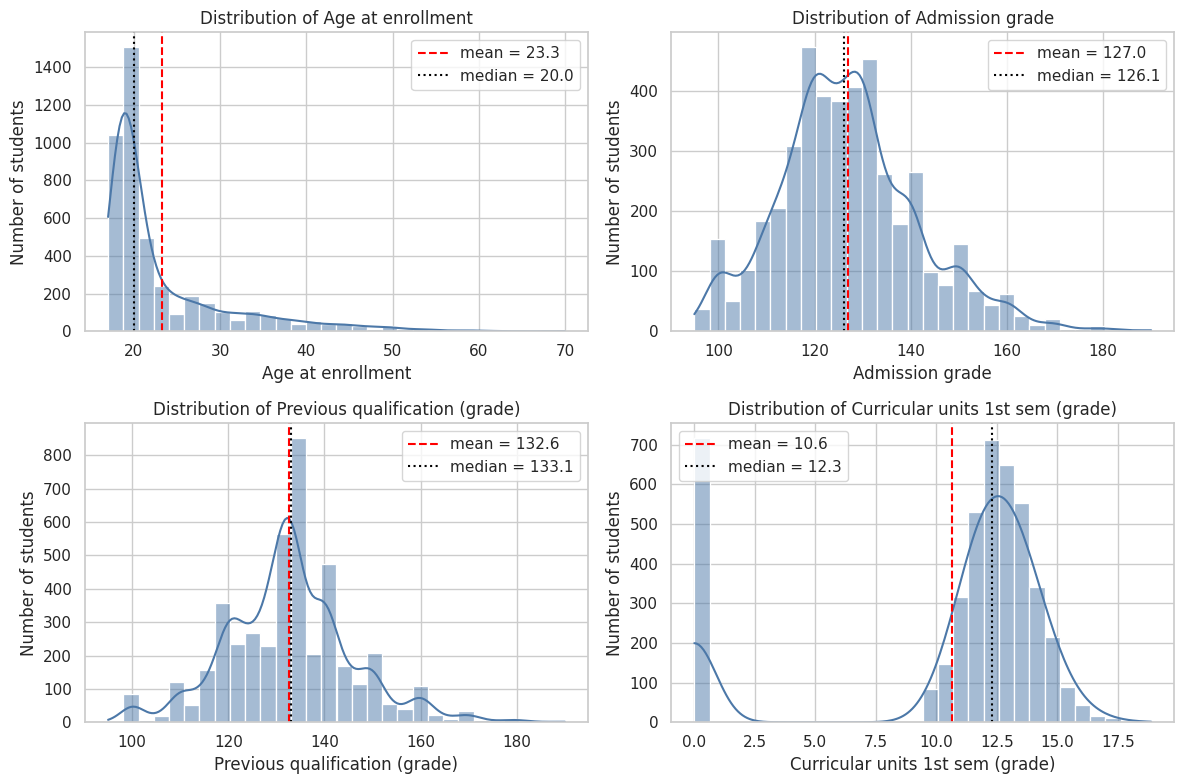

In [5]:
hist_cols = ["Age at enrollment", "Admission grade", "Previous qualification (grade)", "Curricular units 1st sem (grade)"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), hist_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax, color="#4c78a8")
    ax.axvline(df[col].mean(), color="red", linestyle="--", label=f"mean = {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color="black", linestyle=":", label=f"median = {df[col].median():.1f}")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of students")
    ax.legend()
plt.tight_layout()
plt.show()

**Interpretation.**
- **Age at enrollment** is strongly right-skewed (mean 23.3 > median 20): most students start at 18-20, with a long tail of mature students.
- **Admission grade** is roughly bell-shaped around 127 (mean close to median), which is why it will be a reasonable predictor candidate.
- **Previous qualification grade** is similar, centred around 132.
- **First-semester grade** has a visible **spike at 0** (the 718 students discussed above) on top of a main mass around 12-13. This two-part shape (a "no passed units" group plus a normal group) will matter for the hypothesis test.

### Task 7: Preprocessing needed before modelling
1. **Column names:** strip whitespace/tabs (done).
2. **Encoding:** nominal code columns (e.g. `Course`, `Application mode`, occupations) must be **one-hot encoded**. If they were scaled as plain numbers, the model would wrongly assume order and distance between codes.
3. **Scaling:** numerical columns are **standardised** (zero mean, unit variance) so logistic regression regularisation treats them fairly and coefficients are comparable.
4. **Binary columns** are already 0/1 and are passed through.
5. **Split before fitting:** the scaler and encoder are fitted on the **training data only** (inside a scikit-learn `Pipeline`), which prevents information from the test set leaking into training.
6. **Target:** left as three string labels; scikit-learn handles multiclass labels directly.
7. **Feature availability:** decide which variables can legitimately be used for an early prediction (discussed in Part D).

## Part B: Statistical findings - exploratory data analysis

### Task 8-9: Outcome distribution

,Students,Percentage (%)
Target,,
Dropout,1421,32.1
Enrolled,794,17.9
Graduate,2209,49.9


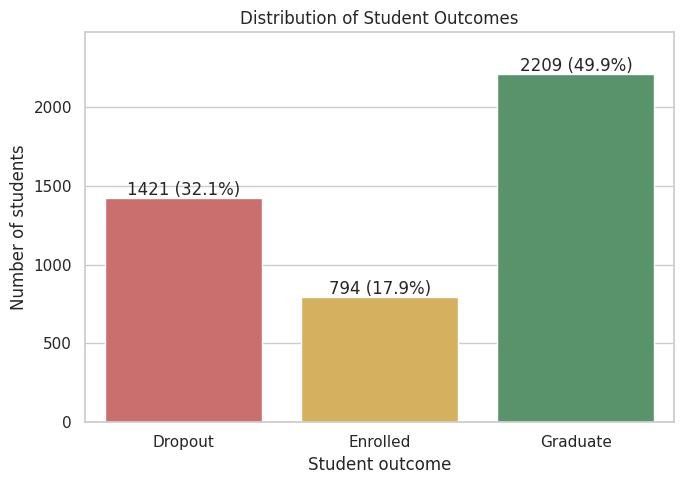

In [6]:
counts = df[target].value_counts().reindex(ORDER)
percent = (counts / len(df) * 100).round(1)
display(pd.DataFrame({"Students": counts, "Percentage (%)": percent}))

plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x=target, order=ORDER, palette=PALETTE)
for i, (c, p) in enumerate(zip(counts, percent)):
    ax.text(i, c + 20, f"{c} ({p}%)", ha="center")
plt.title("Distribution of Student Outcomes")
plt.xlabel("Student outcome")
plt.ylabel("Number of students")
plt.ylim(0, counts.max() * 1.12)
plt.tight_layout()
plt.show()

**Interpretation.** About half of the students (**49.9%**) graduated, **32.1%** dropped out and only **17.9%** are still enrolled. The classes are **imbalanced**: Enrolled is roughly 3 times smaller than Graduate. A model that simply predicts "Graduate" for everyone would already be right about 50% of the time, so accuracy alone will be a misleading metric (see Part D).

### Task 10: Descriptive statistics of selected numerical variables

In [7]:
selected = ["Age at enrollment", "Admission grade", "Previous qualification (grade)",
            "Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)"]
display(df[selected].describe().round(2).T)

print("Skewness:")
print(df[selected].skew().round(2))

,count,mean,std,min,25%,50%,75%,max
Age at enrollment,4424.0,23.27,7.59,17.0,19.0,20.00,25.0,70.00
Admission grade,4424.0,126.98,14.48,95.0,117.9,126.10,134.8,190.00
Previous qualification (grade),4424.0,132.61,13.19,95.0,125.0,133.10,140.0,190.00
Curricular units 1st sem (approved),4424.0,4.71,3.09,0.0,3.0,5.00,6.0,26.00
Curricular units 1st sem (grade),4424.0,10.64,4.84,0.0,11.0,12.29,13.4,18.88


Skewness:
Age at enrollment                      2.05
Admission grade                        0.53
Previous qualification (grade)         0.31
Curricular units 1st sem (approved)    0.77
Curricular units 1st sem (grade)      -1.57
dtype: float64


**Interpretation.** Age has the largest skewness (positive, driven by mature students). Admission and previous grades have small standard deviations relative to their means, so most students are quite similar at entry. First-semester approved units average about 4.7 out of roughly 6 enrolled, but the minimum is 0, again showing the group of students who pass nothing.

### Task 11: Do admission grades differ across outcomes?

,count,mean,median,std
Target,,,,
Dropout,1421,124.96,123.6,15.13
Enrolled,794,125.53,124.1,13.79
Graduate,2209,128.79,127.4,14.07


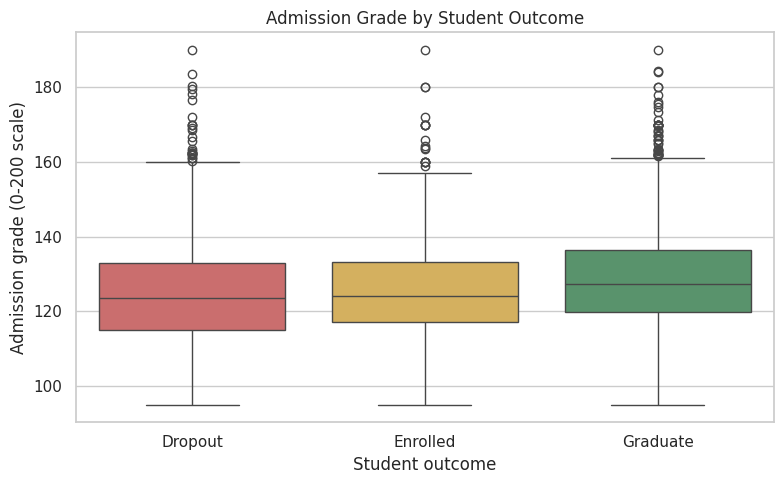

In [8]:
display(df.groupby(target)["Admission grade"].agg(["count", "mean", "median", "std"]).reindex(ORDER).round(2))

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x=target, y="Admission grade", order=ORDER, palette=PALETTE)
plt.title("Admission Grade by Student Outcome")
plt.xlabel("Student outcome")
plt.ylabel("Admission grade (0-200 scale)")
plt.tight_layout()
plt.show()

**Interpretation.** Graduates have a slightly higher admission grade (mean about 128.8) than Dropouts (about 125.0) and Enrolled students (about 125.5), a gap of only ~4 points on a scale where the standard deviation is about 14. The boxes overlap heavily. So admission grade has a **small association** with the outcome: it is not a strong stand-alone separator.

### Task 12: First-semester performance and the final outcome

Curricular units 1st sem (grade)         \
                                     mean median   
Target                                             
Dropout                              7.26  10.93   
Enrolled                            11.13  12.00   
Graduate                            12.64  13.00   

         Curricular units 1st sem (approved)         
                                        mean median  
Target                                               
Dropout                                 2.55    2.0  
Enrolled                                4.32    5.0  
Graduate                                6.23    6.0

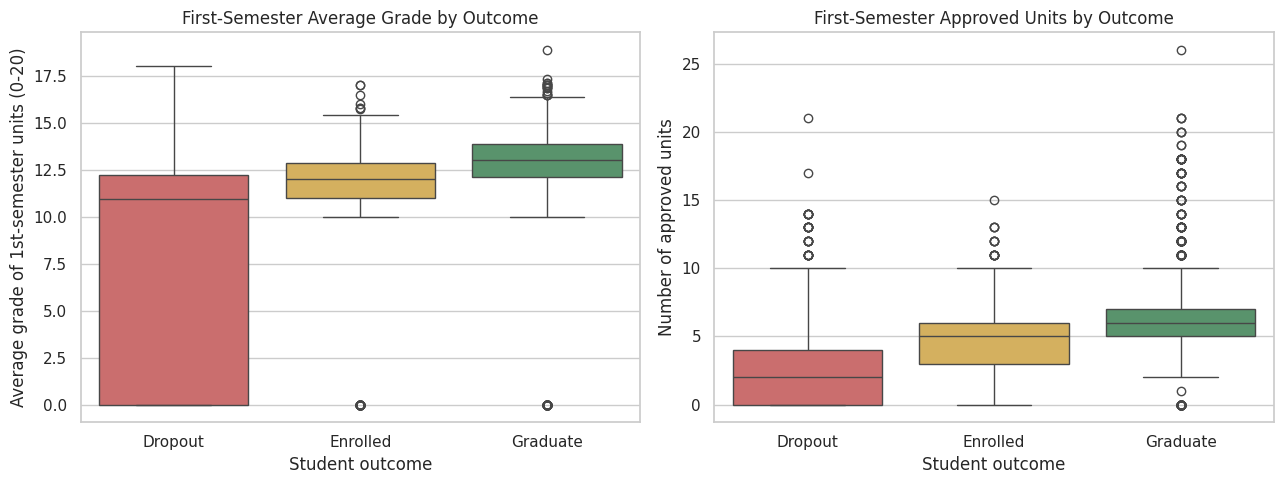

In [9]:
first_sem = ["Curricular units 1st sem (grade)", "Curricular units 1st sem (approved)"]
display(df.groupby(target)[first_sem].agg(["mean", "median"]).reindex(ORDER).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df, x=target, y="Curricular units 1st sem (grade)", order=ORDER, palette=PALETTE, ax=axes[0])
axes[0].set_title("First-Semester Average Grade by Outcome")
axes[0].set_xlabel("Student outcome")
axes[0].set_ylabel("Average grade of 1st-semester units (0-20)")
sns.boxplot(data=df, x=target, y="Curricular units 1st sem (approved)", order=ORDER, palette=PALETTE, ax=axes[1])
axes[1].set_title("First-Semester Approved Units by Outcome")
axes[1].set_xlabel("Student outcome")
axes[1].set_ylabel("Number of approved units")
plt.tight_layout()
plt.show()

**Interpretation.** First-semester performance separates the outcomes much more clearly than admission grade. The mean first-semester grade is **7.3 for Dropouts, 11.1 for Enrolled and 12.6 for Graduates**, and the median number of approved units is **2 for Dropouts versus 6 for Graduates**. Dropouts also have the widest spread and account for most of the zero-grade students (570 of 718). This suggests that a poor first semester is an early warning signal (an association, not proof of cause).

### Task 13: Age at enrollment and outcome

,mean,median,std
Target,,,
Dropout,26.07,23.0,8.70
Enrolled,22.37,20.0,6.30
Graduate,21.78,19.0,6.69


Target,Dropout,Enrolled,Graduate
Age band,,,
<=19,21.0,17.0,62.1
20-22,25.9,22.6,51.5
23-25,43.4,22.6,34.0
26-30,59.8,14.9,25.3
>30,53.6,12.7,33.7


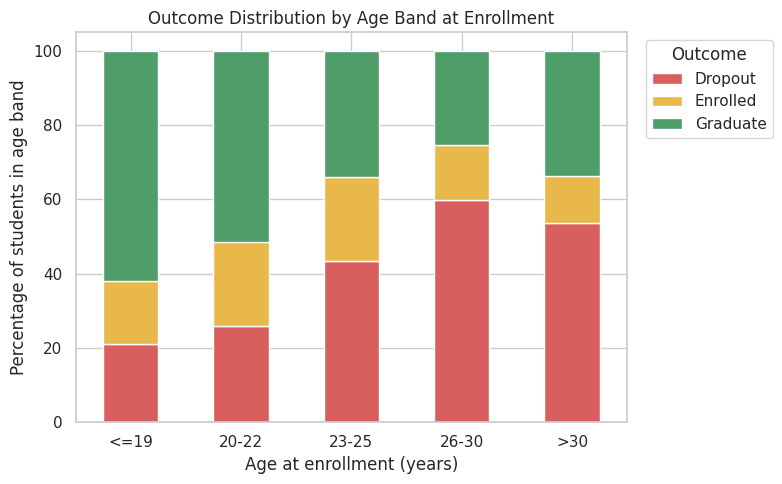

In [10]:
display(df.groupby(target)["Age at enrollment"].agg(["mean", "median", "std"]).reindex(ORDER).round(2))

df["Age band"] = pd.cut(df["Age at enrollment"], [0, 19, 22, 25, 30, 100],
                        labels=["<=19", "20-22", "23-25", "26-30", ">30"])
age_outcome = pd.crosstab(df["Age band"], df[target], normalize="index")[ORDER] * 100
display(age_outcome.round(1))

age_outcome.plot(kind="bar", stacked=True, color=[PALETTE[o] for o in ORDER], figsize=(8, 5))
plt.title("Outcome Distribution by Age Band at Enrollment")
plt.xlabel("Age at enrollment (years)")
plt.ylabel("Percentage of students in age band")
plt.legend(title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretation.** Older entrants drop out much more often. The dropout share rises from about **21% for students aged 19 or under** to about **60% for ages 26-30**, while the graduate share falls from 62% to 25%. Mature students often balance work and family, but this data cannot tell us *why*, so I only report the association.

### Task 14: Three further findings (support, fees and debt)

Target,Dropout,Enrolled,Graduate
No,38.7,20.0,41.3
Yes,12.2,11.8,76.0


Target,Dropout,Enrolled,Graduate
No,86.6,8.0,5.5
Yes,24.7,19.3,56.0


Target,Dropout,Enrolled,Graduate
No,28.3,18.0,53.8
Yes,62.0,17.9,20.1


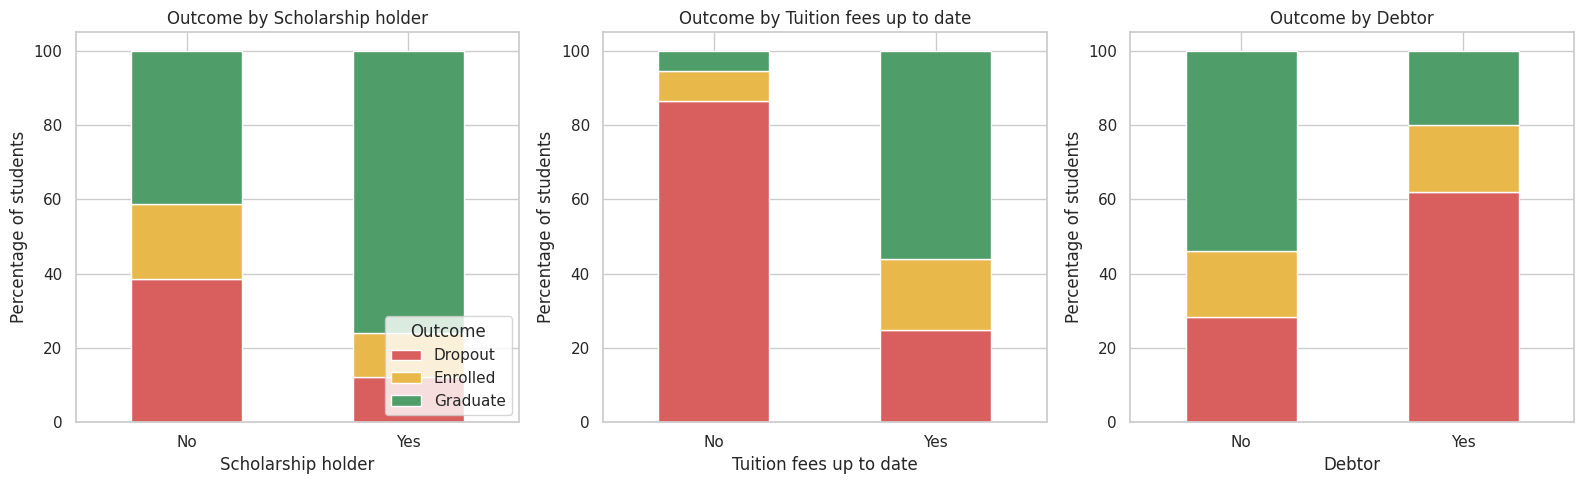

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col, labels in zip(axes, ["Scholarship holder", "Tuition fees up to date", "Debtor"],
                           [["No", "Yes"]] * 3):
    tab = pd.crosstab(df[col], df[target], normalize="index")[ORDER] * 100
    tab.index = labels
    tab.plot(kind="bar", stacked=True, color=[PALETTE[o] for o in ORDER], ax=ax, legend=False)
    ax.set_title(f"Outcome by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Percentage of students")
    ax.tick_params(axis="x", rotation=0)
    display(tab.round(1))
axes[0].legend(title="Outcome", loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation (three findings).**
1. **Scholarship holders** graduate far more often (**76%**) than non-holders (41%), and only 12% of them drop out versus 39%.
2. **Tuition fees not up to date** is the strongest single warning sign here: **86.6%** of those students dropped out, versus 24.7% of those with fees up to date.
3. **Debtors** drop out at **62%** versus 28% for non-debtors.

These are strong *associations* linked to financial situation, but they do not prove that money problems cause dropout; they may also reflect disengagement before dropping out (a student who has already decided to leave may stop paying fees).

## Part C: Statistical findings - hypothesis testing

### Task 15: Hypotheses
Research question: *Do first-semester grades differ between students with different final outcomes (Dropout, Enrolled, Graduate)?*

- **H0:** The distribution (central value) of the first-semester average grade is the same for Dropout, Enrolled and Graduate students.
- **H1:** At least one outcome group has a different first-semester grade distribution.

### Task 16-17: Choice of test and assumptions
There are **three independent groups** and a numeric response, so the classical choice is **one-way ANOVA**. Its assumptions are independence, normality within each group, and equal variances. I check normality (Shapiro-Wilk) and equal variances (Levene) before deciding.

Shapiro-Wilk normality test per group:
  Dropout   n=1421  W=0.745  p=3.16e-42  skew=-0.31
  Enrolled  n= 794  W=0.629  p=3.62e-38  skew=-2.36
  Graduate  n=2209  W=0.617  p=6.71e-57  skew=-3.45

Levene test for equal variances: W=549.9, p=5.47e-214


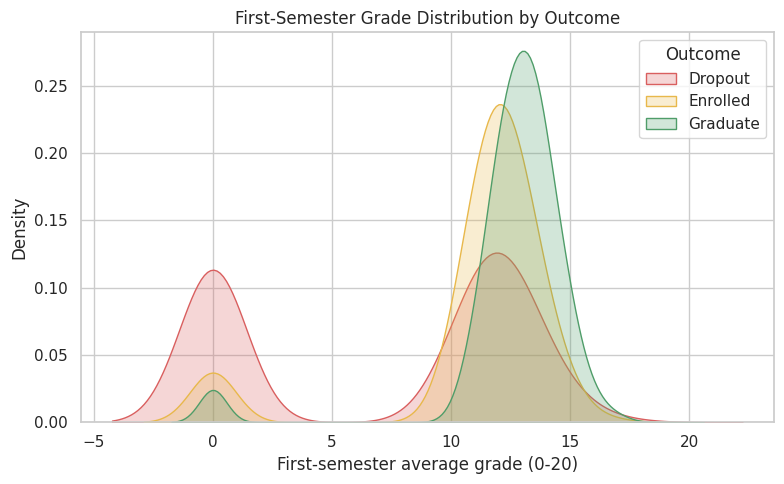

In [12]:
g = "Curricular units 1st sem (grade)"
groups = {o: df.loc[df[target] == o, g] for o in ORDER}

print("Shapiro-Wilk normality test per group:")
for o, x in groups.items():
    stat, p = stats.shapiro(x)
    print(f"  {o:9s} n={len(x):4d}  W={stat:.3f}  p={p:.2e}  skew={x.skew():.2f}")

lev = stats.levene(*groups.values())
print(f"\nLevene test for equal variances: W={lev.statistic:.1f}, p={lev.pvalue:.2e}")

plt.figure(figsize=(8, 5))
for o in ORDER:
    sns.kdeplot(groups[o], label=o, color=PALETTE[o], fill=True, alpha=.25)
plt.title("First-Semester Grade Distribution by Outcome")
plt.xlabel("First-semester average grade (0-20)")
plt.ylabel("Density")
plt.legend(title="Outcome")
plt.tight_layout()
plt.show()

**Assessment of assumptions.**
- **Independence:** each row is a different student, so this is reasonable.
- **Normality:** Shapiro-Wilk gives p-values far below 0.05 for all three groups, and the density plot shows a spike at 0 and a left skew. The normality assumption is **not** satisfied (with n in the thousands the test is very sensitive, but the plot confirms the problem).
- **Equal variances:** Levene's test is also strongly significant, so variances differ (Dropouts are far more spread out).

Because both assumptions are violated, I use the **Kruskal-Wallis H test** (a rank-based, non-parametric alternative to ANOVA that does not need normality or equal variances) as the main test, and report ANOVA only as a cross-check. With such large samples ANOVA is fairly robust, so I expect both tests to agree.

In [13]:
alpha = 0.05
kw = stats.kruskal(*groups.values())
anova = stats.f_oneway(*groups.values())

n_total = len(df)
eps_sq = (kw.statistic - len(ORDER) + 1) / (n_total - len(ORDER))   # epsilon-squared effect size for Kruskal-Wallis

grand = df[g].mean()
eta_sq = sum(len(x) * (x.mean() - grand) ** 2 for x in groups.values()) / ((df[g] - grand) ** 2).sum()

print(f"Kruskal-Wallis:  H = {kw.statistic:.1f}, df = 2, p = {kw.pvalue:.2e}  -> {'reject H0' if kw.pvalue < alpha else 'fail to reject H0'}")
print(f"One-way ANOVA:   F = {anova.statistic:.1f}, p = {anova.pvalue:.2e}  (cross-check)")
print(f"Effect size: epsilon-squared = {eps_sq:.3f}, eta-squared = {eta_sq:.3f}")

# Post-hoc pairwise Mann-Whitney U tests with Bonferroni correction (3 comparisons)
from itertools import combinations
rows = []
for a, b in combinations(ORDER, 2):
    u = stats.mannwhitneyu(groups[a], groups[b], alternative="two-sided")
    rows.append({"Comparison": f"{a} vs {b}", "U": u.statistic,
                 "p (Bonferroni)": min(u.pvalue * 3, 1.0),
                 "Median difference": groups[b].median() - groups[a].median()})
display(pd.DataFrame(rows).round(4))

# Sensitivity check: exclude students whose 1st-semester grade is exactly 0
nz = df[df[g] > 0]
kw_nz = stats.kruskal(*[nz.loc[nz[target] == o, g] for o in ORDER])
print(f"\nSensitivity (excluding grade = 0, n={len(nz)}): H = {kw_nz.statistic:.1f}, p = {kw_nz.pvalue:.2e}")

Kruskal-Wallis:  H = 1094.2, df = 2, p = 2.51e-238  -> reject H0
One-way ANOVA:   F = 713.5, p = 2.80e-269  (cross-check)
Effect size: epsilon-squared = 0.247, eta-squared = 0.244


,Comparison,U,p (Bonferroni),Median difference
0,Dropout vs Enrolled,368443.5,0.0,1.0714
1,Dropout vs Graduate,600098.0,0.0,2.0714
2,Enrolled vs Graduate,524677.0,0.0,1.0000



Sensitivity (excluding grade = 0, n=3706): H = 474.5, p = 9.34e-104


### Task 18-19: Result and conclusion
At the 0.05 significance level the Kruskal-Wallis test gives **H ≈ 1094, p ≈ 2.5 × 10⁻²³⁸**, so we **reject H0**: first-semester grades differ between outcome groups. ANOVA agrees (F ≈ 714, p ≈ 10⁻²⁶⁹). Post-hoc pairwise tests (Bonferroni-corrected) show that **all three pairs differ significantly**; the Dropout group has by far the lowest grades.

**Statistical significance versus practical importance.** A tiny p-value is expected with 4,424 students, so I also look at the effect size. Epsilon-squared ≈ **0.25** (eta-squared ≈ 0.24), which is a **large** effect: about a quarter of the variation in first-semester grade is associated with the outcome group. The result is therefore not just statistically significant but practically meaningful.

**Robustness.** The result still holds (H ≈ 474, p ≈ 10⁻¹⁰⁴) after removing the 718 zero-grade students, so the conclusion is not driven only by those students.

**Caution:** this shows that grades and outcomes are *associated*; it does not show that low first-semester grades *cause* dropout.

## Part D: Model building and model evaluation

### Which variables are genuinely available for an *early* prediction?
The original target describes the status at the *end* of the normal course duration. If a prediction is meant to help the institution act early, it should only use information known by then. The **second-semester** variables (units credited, enrolled, evaluated, approved, grade) describe what happens *after* much of the dropout has already occurred: for example the median second-semester grade of Dropouts is 0 because many have already left. Using them would make the model look more accurate but it would not be a true early warning.

I therefore build:
- **Model A (early-warning model, main model):** enrolment information + **first-semester** performance + macroeconomic indicators. No second-semester columns.
- **Model B (full-information reference):** all 36 predictors, used only to show how much accuracy is gained once second-semester data is known.

### Task 20-22: Predictors/target, split and preprocessing
**Split strategy:** an 80/20 **stratified** hold-out split (`stratify=y`), so the Dropout/Enrolled/Graduate proportions are the same in training and test sets. This matters because Enrolled is the small class. I also use 5-fold stratified cross-validation to check that the result is stable and not an accident of one split.

In [14]:
y = df[target]
X = df.drop(columns=[target, "Age band"])

second_sem_cols = [c for c in X.columns if "2nd sem" in c]
print("Second-semester columns excluded from the early-warning model:", len(second_sem_cols))

def make_pipeline(feature_cols, class_weight=None):
    nums = [c for c in feature_cols if c in numerical_cols]
    cats = [c for c in feature_cols if c in categorical_cols]
    bins = [c for c in feature_cols if c in binary_cols]
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cats),   # nominal codes -> one-hot
        ("num", StandardScaler(), nums),                          # numeric -> standardised
        ("bin", "passthrough", bins),                             # already 0/1
    ])
    clf = LogisticRegression(max_iter=3000, class_weight=class_weight)  # multinomial logistic regression
    return Pipeline([("prep", pre), ("model", clf)])

early_cols = [c for c in X.columns if c not in second_sem_cols]
full_cols = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("\nClass proportions (train vs test):")
print(pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)}).round(3))

Second-semester columns excluded from the early-warning model: 6
Train: (3539, 36)  Test: (885, 36)

Class proportions (train vs test):
          train   test
Target                
Graduate  0.499  0.499
Dropout   0.321  0.321
Enrolled  0.179  0.180


### Task 23-24: Train multiclass logistic regression and predict

In [15]:
model_a = make_pipeline(early_cols).fit(X_train[early_cols], y_train)             # main model
model_a_bal = make_pipeline(early_cols, "balanced").fit(X_train[early_cols], y_train)   # to study class imbalance
model_b = make_pipeline(full_cols).fit(X_train[full_cols], y_train)               # full-information reference

pred_a = model_a.predict(X_test[early_cols])
pred_a_bal = model_a_bal.predict(X_test[early_cols])
pred_b = model_b.predict(X_test[full_cols])
print("Models trained and predictions generated for the test set.")

Models trained and predictions generated for the test set.


### Task 25: Confusion matrix of the main model

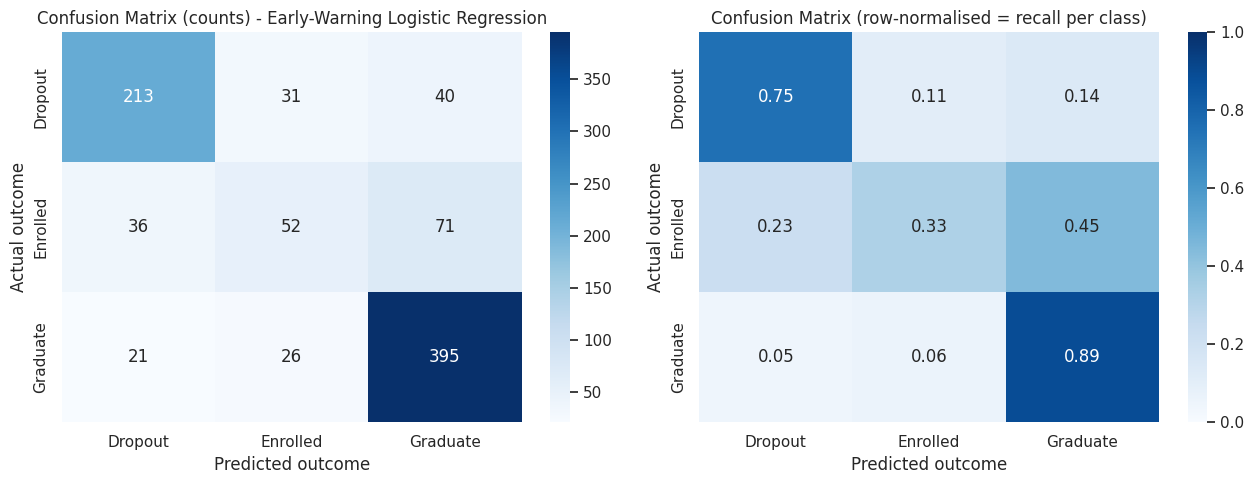

In [16]:
cm = confusion_matrix(y_test, pred_a, labels=ORDER)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ORDER, yticklabels=ORDER, ax=axes[0])
axes[0].set_title("Confusion Matrix (counts) - Early-Warning Logistic Regression")
axes[0].set_xlabel("Predicted outcome")
axes[0].set_ylabel("Actual outcome")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=ORDER, yticklabels=ORDER, ax=axes[1], vmin=0, vmax=1)
axes[1].set_title("Confusion Matrix (row-normalised = recall per class)")
axes[1].set_xlabel("Predicted outcome")
axes[1].set_ylabel("Actual outcome")
plt.tight_layout()
plt.show()

**Interpretation.** Out of 284 real Dropouts the model identifies 213 (75%), and out of 442 Graduates it identifies 395 (89%). The weak spot is **Enrolled**: of 159 Enrolled students only 52 (33%) are recognised, and 71 of them are predicted as Graduate. Enrolled students sit "between" the two other outcomes (they have not yet dropped out or graduated), so they are inherently harder to separate.

### Task 26-27: Accuracy, precision, recall, F1 and macro averages

In [17]:
def performance_table(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=ORDER, zero_division=0)
    t = pd.DataFrame({"Precision": p, "Recall": r, "F1-score": f, "Support": s}, index=ORDER)
    t.loc["Macro average"] = [p.mean(), r.mean(), f.mean(), s.sum()]
    t.loc["Weighted average"] = [np.average(p, weights=s), np.average(r, weights=s), np.average(f, weights=s), s.sum()]
    return t

perf_a = performance_table(y_test, pred_a)
print("Early-warning logistic regression (main model): accuracy =", round(accuracy_score(y_test, pred_a), 3))
display(perf_a.round(3))

Early-warning logistic regression (main model): accuracy = 0.746


,Precision,Recall,F1-score,Support
Dropout,0.789,0.750,0.769,284.0
Enrolled,0.477,0.327,0.388,159.0
Graduate,0.781,0.894,0.833,442.0
Macro average,0.682,0.657,0.663,885.0
Weighted average,0.729,0.746,0.733,885.0


**Interpretation.** Accuracy is **74.6%**, but the macro-averaged F1 is lower (**0.66**) because the model is much better at Graduate (F1 0.83) and Dropout (F1 0.77) than at Enrolled (F1 0.39). The macro average gives each class equal weight, so it exposes the weakness on the small class that accuracy hides.

### Task 28-29: Per-class performance and the effect of class imbalance
To study imbalance, I compare the main model with a version trained using `class_weight="balanced"` (which makes mistakes on the small class cost more), and with the full-information model B.

,Accuracy,Macro precision,Macro recall,Macro F1,Recall Dropout,Recall Enrolled,Recall Graduate
Model,,,,,,,
A: Early-warning LR (main),0.746,0.682,0.657,0.663,0.750,0.327,0.894
"A: Early-warning LR, balanced weights",0.699,0.665,0.668,0.659,0.683,0.560,0.760
B: Full information LR (incl. 2nd semester),0.771,0.718,0.688,0.697,0.761,0.390,0.914



5-fold CV macro-F1 -> A: 0.667 (+/- 0.007) | A balanced: 0.675 (+/- 0.016) | B: 0.702 (+/- 0.011)


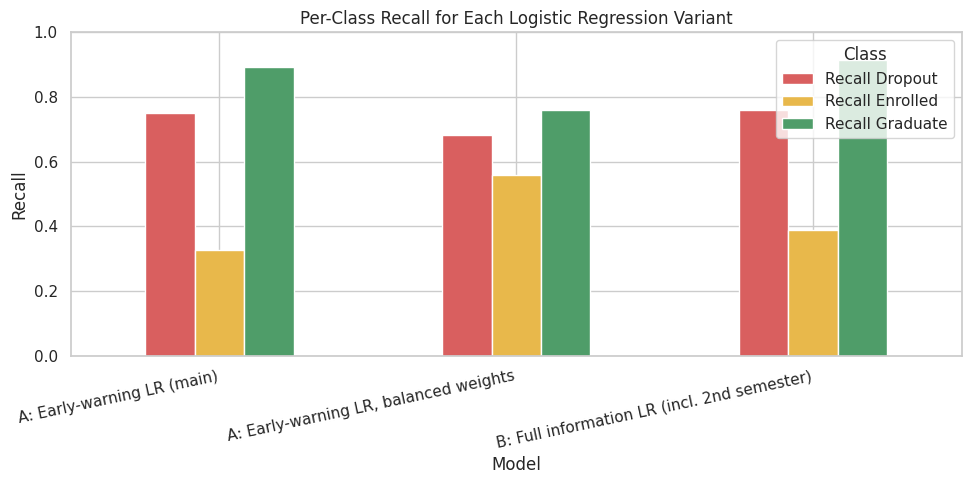

In [18]:
def summary_row(name, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, labels=ORDER, zero_division=0)
    return {"Model": name, "Accuracy": accuracy_score(y_test, y_pred),
            "Macro precision": p.mean(), "Macro recall": r.mean(), "Macro F1": f.mean(),
            "Recall Dropout": r[0], "Recall Enrolled": r[1], "Recall Graduate": r[2]}

comparison = pd.DataFrame([
    summary_row("A: Early-warning LR (main)", pred_a),
    summary_row("A: Early-warning LR, balanced weights", pred_a_bal),
    summary_row("B: Full information LR (incl. 2nd semester)", pred_b),
]).set_index("Model")
display(comparison.round(3))

# Stability check with 5-fold stratified cross-validation (macro F1)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_a = cross_val_score(make_pipeline(early_cols), X[early_cols], y, cv=skf, scoring="f1_macro")
cv_ab = cross_val_score(make_pipeline(early_cols, "balanced"), X[early_cols], y, cv=skf, scoring="f1_macro")
cv_b = cross_val_score(make_pipeline(full_cols), X[full_cols], y, cv=skf, scoring="f1_macro")
print(f"\n5-fold CV macro-F1 -> A: {cv_a.mean():.3f} (+/- {cv_a.std():.3f}) | "
      f"A balanced: {cv_ab.mean():.3f} (+/- {cv_ab.std():.3f}) | B: {cv_b.mean():.3f} (+/- {cv_b.std():.3f})")

ax = comparison[["Recall Dropout", "Recall Enrolled", "Recall Graduate"]].plot(kind="bar", figsize=(10, 5), color=[PALETTE[o] for o in ORDER])
ax.set_title("Per-Class Recall for Each Logistic Regression Variant")
ax.set_xlabel("Model")
ax.set_ylabel("Recall")
ax.set_ylim(0, 1)
plt.xticks(rotation=12, ha="right")
plt.legend(title="Class")
plt.tight_layout()
plt.show()

**Interpretation.**
- **Class imbalance matters.** The plain model reaches 74.6% accuracy but recognises only **33%** of Enrolled students. Using balanced class weights raises Enrolled recall to **56%**, but it lowers overall accuracy to about 70% and Dropout recall to 68%. Macro F1 stays almost the same (0.66), so this is a **trade-off**, not a free improvement. Which version is better depends on the cost of missing a student: if the goal is to find at-risk students, the balanced version catches more Enrolled students but misses more Dropouts.
- **Early vs full information.** Adding second-semester data (model B) raises accuracy from 74.6% to about 77.1% and macro F1 from 0.66 to about 0.70. The gain is modest, which supports using the first-semester data for an early warning without losing much.
- **Stability.** Cross-validated macro F1 values (about 0.67 for the early-warning model) agree with the hold-out result, so it is not a lucky split.

### Extra comparison: Random Forest (optional)
As a non-linear benchmark I also fit a Random Forest on the same early-warning features. It is not required by the case study, but it shows whether the linear model is missing important non-linear patterns.

In [19]:
rf_pipe = Pipeline([
    ("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), [c for c in early_cols if c in categorical_cols]),
                                ("rest", "passthrough", [c for c in early_cols if c not in categorical_cols])])),
    ("model", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1)),
]).fit(X_train[early_cols], y_train)
pred_rf = rf_pipe.predict(X_test[early_cols])
display(pd.DataFrame([summary_row("A: Early-warning LR (main)", pred_a),
                      summary_row("Random Forest (early-warning features)", pred_rf)]).set_index("Model").round(3))

,Accuracy,Macro precision,Macro recall,Macro F1,Recall Dropout,Recall Enrolled,Recall Graduate
Model,,,,,,,
A: Early-warning LR (main),0.746,0.682,0.657,0.663,0.750,0.327,0.894
Random Forest (early-warning features),0.727,0.655,0.615,0.616,0.718,0.208,0.919


**Interpretation.** The Random Forest does **not** beat logistic regression on this feature set: it has slightly lower accuracy (72.7% vs 74.6%), lower macro F1 (0.62 vs 0.66) and an even weaker recall for the Enrolled class (21% vs 33%). So there is no evidence that non-linear patterns are being missed, and logistic regression, which is also much easier to explain, is a sound choice for the main model.

## Part E: Interpretation and recommendations

### Task 30-31: Which variables are associated with outcomes? (logistic regression coefficients)

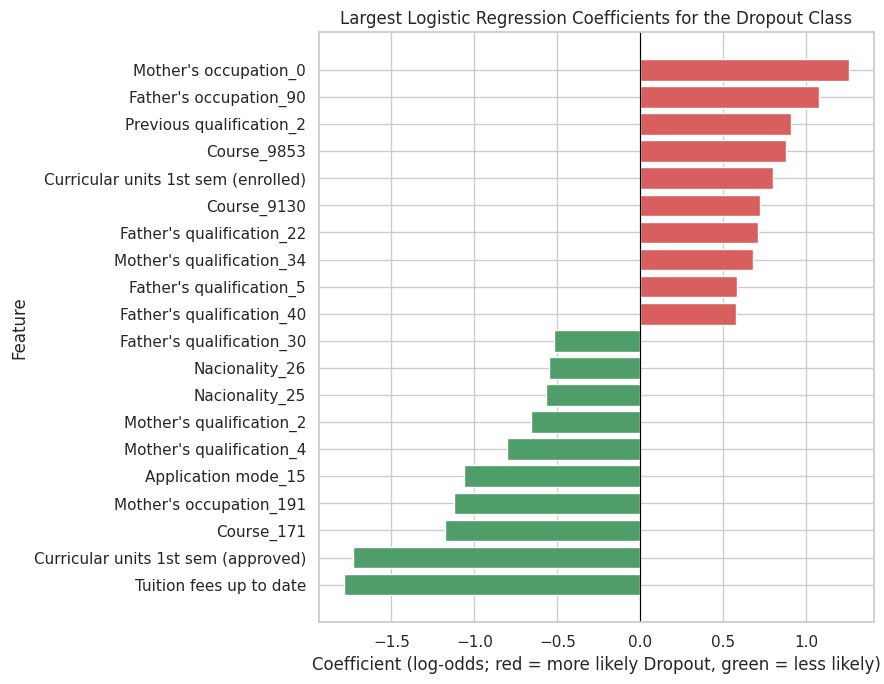

,Coefficient,Odds ratio (exp)
Mother's occupation_0,1.256,3.512
Father's occupation_90,1.080,2.943
Previous qualification_2,0.908,2.478
Course_9853,0.881,2.413
Curricular units 1st sem (enrolled),0.802,2.230
Course_9130,0.722,2.059
Father's qualification_22,0.709,2.031
Mother's qualification_34,0.681,1.976
Father's qualification_5,0.583,1.791
Father's qualification_40,0.574,1.775


In [20]:
prep = model_a.named_steps["prep"]
lr = model_a.named_steps["model"]
feature_names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
coef = pd.DataFrame(lr.coef_.T, index=feature_names, columns=lr.classes_)

# Dropout coefficients: positive = higher odds of Dropout (relative to the other classes)
drop_coef = coef["Dropout"].sort_values()
top = pd.concat([drop_coef.head(10), drop_coef.tail(10)])

plt.figure(figsize=(9, 7))
colors = ["#4f9d69" if v < 0 else "#d95f5f" for v in top.values]
plt.barh(top.index, top.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Largest Logistic Regression Coefficients for the Dropout Class")
plt.xlabel("Coefficient (log-odds; red = more likely Dropout, green = less likely)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

odds = pd.DataFrame({"Coefficient": top, "Odds ratio (exp)": np.exp(top)}).round(3)
display(odds.sort_values("Coefficient", ascending=False))

### Reading the coefficients (Task 30-31)
The model is a multinomial logistic regression, so each class has its own set of coefficients. The chart and table above show the Dropout coefficients. Numeric variables were standardised, so their coefficients are *per one standard deviation*; an odds ratio below 1 means lower odds of Dropout and above 1 means higher odds, with all other variables held fixed.

- **Tuition fees up to date** (coefficient -1.78, odds ratio 0.17) and **first-semester approved units** (coefficient -1.73, odds ratio 0.18) have the largest negative coefficients: students with fees paid and more approved units have much lower odds of dropping out. These agree with the exploratory findings in Part B.
- **First-semester enrolled units** has a *positive* coefficient (0.80, odds ratio 2.2). Holding approved units fixed, a student who enrols in many units but passes few is at higher risk. In other words the *gap* between units attempted and units passed is what matters.
- Several **category-code coefficients** appear (certain courses, parents' occupations and qualifications, some application modes). The codes are labels from the data dictionary, and many of these categories contain only a handful of students, so their large coefficients are **unstable** and should not be over-interpreted. The course effect (e.g. course 171 has lower dropout odds, course 9853 higher) mostly shows that dropout differs between programmes.
- Variables such as age, debtor status, scholarship and gender are not among the 20 largest coefficients in this multivariable model. Their raw associations seen in Part B are partly **shared with** fees status and first-semester performance (variables are correlated), which is a reminder that a coefficient measures the *additional* association after adjusting for the other variables.

These are predictive associations, not causes.

### Task 32: Limitations

1. **Association, not causation.** Logistic regression coefficients show which variables move together with the outcome after adjusting for the other variables. They do not show that changing a variable would change the outcome. For example, "fees not up to date" may be a *symptom* of a student who is already disengaging.
2. **Weak performance on the Enrolled class** (recall about 33%). Enrolled is a transitional, mixed group (some will graduate late, some will drop out), so predictions for them are unreliable.
3. **Single institution, single time period.** The data comes from one Portuguese institution and one cohort period; the model may not generalise to other universities, countries or later cohorts. Macroeconomic indicators (unemployment, inflation, GDP) take only a few distinct values, so they can partly act as a "cohort year" proxy.
4. **Linear model and one-hot sparsity.** Logistic regression assumes a linear relationship in the log-odds; some course/code categories have very few students, so their coefficients are unstable.
5. **Hold-out evaluation on about 885 students** has sampling noise (the cross-validation helps, but is not a substitute for testing on a genuinely new cohort).
6. **Possible leakage and proxies.** Variables such as tuition status can partly reflect a decision already made. Also, demographic variables (gender, nationality, parents' occupation) could act as proxies for sensitive characteristics.

### Task 33: Recommended interventions (evidence-based)

1. **Early academic-support trigger after the first semester.** Students with few approved first-semester units or a first-semester grade near 0 are overwhelmingly Dropouts (570 of 718 students with a zero grade). *Evidence:* Part B (median 2 approved units for Dropouts vs 6 for Graduates) and the large effect size in Part C (epsilon-squared ≈ 0.25). Offer tutoring, mentoring and a check-in with an advisor before the second semester.
2. **Financial-support outreach.** 86.6% of students whose fees were not up to date and 62% of debtors dropped out, while scholarship holders dropped out far less (12% vs 39%). *Action to investigate:* flexible payment plans, emergency funds and wider scholarship awareness, with a trial to measure whether they actually reduce dropout.
3. **Support for mature entrants.** The dropout share rises from about 21% (age 19 or under) to about 60% (26-30). *Action to investigate:* part-time or evening options, flexible deadlines, and childcare/work-balance counselling for students over 23.
4. **Monitor, then test.** Pilot any intervention on a subset, compare dropout rates against a similar control group, and review after one year; do not assume the associations found here will be causal.

### Task 34: Using the model responsibly

- Use predictions only as a **prompt for a supportive conversation** (extra tutoring, advice), never to deny admission, funding or places.
- Keep a **human advisor in the loop**; the model has only ~75% accuracy and is weak for Enrolled students, so many students would be flagged wrongly or missed.
- **Do not use sensitive or proxy variables** (gender, nationality, parental background) to single out groups, and check performance separately across groups for fairness before deployment.
- Tell students that such a tool is used, explain it in plain language, and protect their data.
- **Retrain and re-validate** each year, because cohorts and economic conditions change.
- Avoid stigmatising labels such as "dropout risk" in student records; report them as "may benefit from additional support".

## Conclusion

Of the 4,424 students, 49.9% graduated, 32.1% dropped out and 17.9% remained enrolled. Admission grade has only a small association with the outcome, whereas **first-semester performance, tuition-fee status, debt, scholarship status and age at enrollment** show strong associations. The hypothesis test (Kruskal-Wallis, p < 0.001, epsilon-squared ≈ 0.25) shows that first-semester grades differ strongly and meaningfully across the three outcomes. An early-warning multinomial logistic regression that uses only information available by the end of the first semester reaches **74.6% accuracy and a macro F1 of 0.66** (cross-validated 0.67), which is close to the model that also uses second-semester data (macro F1 about 0.70). The model is good at identifying Graduates and Dropouts but weak at identifying Enrolled students, and class imbalance means accuracy alone is misleading. The findings suggest practical, supportive interventions (academic, financial and mature-student support), but they are associations only and should be used responsibly, with human judgement and a pilot-and-evaluate approach.

## References
- Realinho, V., Machado, J., Baptista, L., Martins, M. V. (2021). *Predict Students' Dropout and Academic Success*. UCI Machine Learning Repository.
- scikit-learn and SciPy documentation (logistic regression, pipelines, Kruskal-Wallis, Levene, Shapiro-Wilk).
